<a href="https://colab.research.google.com/github/ssb60386-beep/AI-LAB/blob/main/LAB_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = iris.target

# Display the first five rows
print("First five rows:")
print(df.head())

# Display dataset information
print("\nDataset information:")
print(df.info())

print("\nDataset shape:")
print(df.shape)

print("\nMissing values:")
print(df.isnull().sum())

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species  
0        0  
1        0  
2        0  
3        0  
4        0  

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species    

In [3]:
# Input features
X = df[iris.feature_names]

# Target variable
y = iris.target

print("Input features:")
print(X.head())

print("\nTarget species:")
print(iris.target_names)

print("\nNumber of samples per species:")
print(df["species"].value_counts().sort_index())

Input features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target species:
['setosa' 'versicolor' 'virginica']

Number of samples per species:
species
0    50
1    50
2    50
Name: count, dtype: int64


Statistical summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  

Species distribution:
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


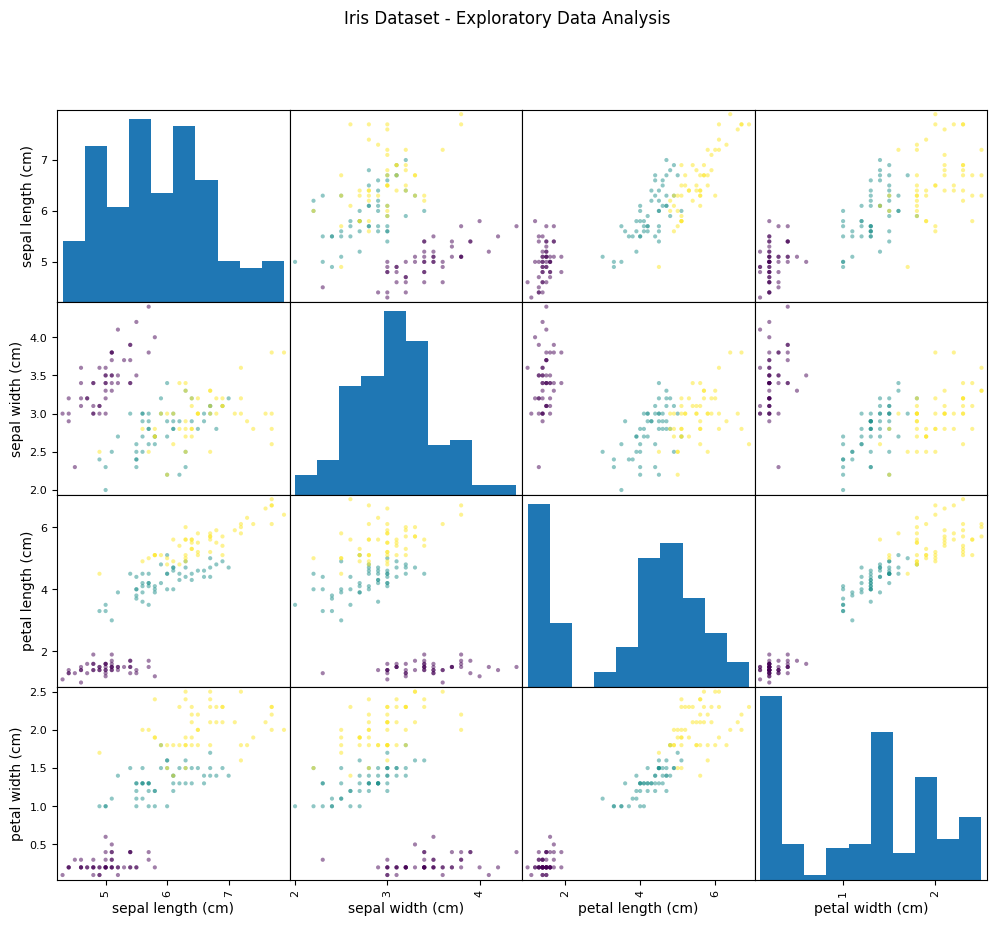

In [4]:
# Statistical summary
print("Statistical summary:")
print(X.describe())

# Species distribution
print("\nSpecies distribution:")
print(pd.Series(
    iris.target_names[y]
).value_counts())

# Plot feature relationships
pd.plotting.scatter_matrix(
    X,
    figsize=(12, 10),
    c=y,
    diagonal="hist",
    cmap="viridis"
)

plt.suptitle("Iris Dataset - Exploratory Data Analysis")
plt.show()

In [5]:
print("Missing values:", X.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Data types:")
print(X.dtypes)

Missing values: 0
Duplicate rows: 1
Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [7]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [8]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Species": iris.target_names[y_test],
    "Predicted Species": iris.target_names[y_pred]
})

print(results.to_string(index=False))

Actual Species Predicted Species
        setosa            setosa
     virginica         virginica
    versicolor        versicolor
    versicolor        versicolor
        setosa            setosa
    versicolor        versicolor
        setosa            setosa
        setosa            setosa
     virginica         virginica
    versicolor        versicolor
     virginica         virginica
     virginica         virginica
     virginica         virginica
    versicolor        versicolor
        setosa            setosa
        setosa            setosa
        setosa            setosa
    versicolor        versicolor
    versicolor        versicolor
     virginica         virginica
        setosa            setosa
     virginica         virginica
    versicolor        versicolor
     virginica         virginica
     virginica         virginica
    versicolor         virginica
    versicolor        versicolor
        setosa            setosa
     virginica         virginica
        se

In [9]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names,
    zero_division=0
))

Accuracy:  0.9667
Precision: 0.9697
Recall:    0.9667
F1-score:  0.9666

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


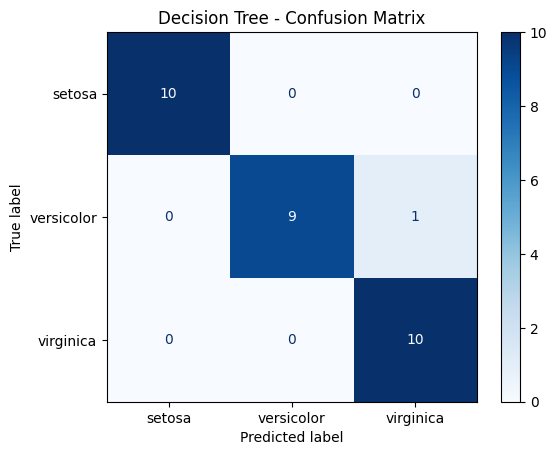

In [10]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues")
plt.title("Decision Tree - Confusion Matrix")
plt.show()

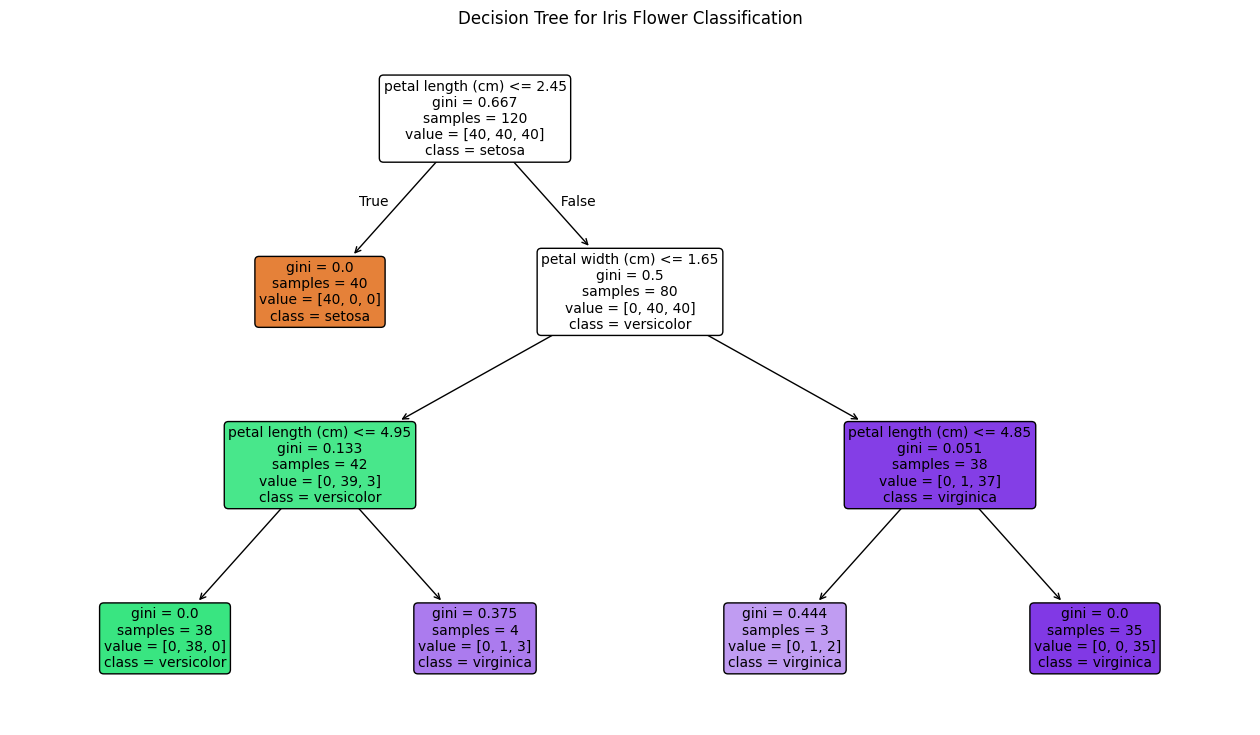

In [11]:
plt.figure(figsize=(16, 9))

plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree for Iris Flower Classification")
plt.show()

**Question no: 02**


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import (
    load_breast_cancer,
    load_wine,
    load_diabetes
)

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
cancer = load_breast_cancer()

X_cancer = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

y_cancer = cancer.target

print("Breast Cancer Dataset")
print("Shape:", X_cancer.shape)
print("Features:", X_cancer.shape[1])
print("Target classes:", cancer.target_names)
print("\nFirst five rows:")
print(X_cancer.head())

print("\nMissing values:", X_cancer.isnull().sum().sum())
print("\nClass distribution:")
print(pd.Series(y_cancer).value_counts().sort_index())

Breast Cancer Dataset
Shape: (569, 30)
Features: 30
Target classes: ['malignant' 'benign']

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430   

In [3]:
wine = load_wine()

X_wine = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

y_wine = wine.target

print("Wine Recognition Dataset")
print("Shape:", X_wine.shape)
print("Features:", X_wine.shape[1])
print("Target classes:", wine.target_names)
print("\nFirst five rows:")
print(X_wine.head())

print("\nMissing values:", X_wine.isnull().sum().sum())
print("\nClass distribution:")
print(pd.Series(y_wine).value_counts().sort_index())

Wine Recognition Dataset
Shape: (178, 13)
Features: 13
Target classes: ['class_0' 'class_1' 'class_2']

First five rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69        

In [4]:
diabetes = load_diabetes()

X_diabetes = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

y_diabetes = diabetes.target

print("Diabetes Dataset")
print("Shape:", X_diabetes.shape)
print("Features:", X_diabetes.shape[1])
print("\nFirst five rows:")
print(X_diabetes.head())

print("\nMissing values:", X_diabetes.isnull().sum().sum())
print("\nTarget statistics:")
print(pd.Series(y_diabetes).describe())

Diabetes Dataset
Shape: (442, 10)
Features: 10

First five rows:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  

Missing values: 0

Target statistics:
count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
dtype: float64


Cancer feature statistics:
       mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
count       569.00        569.00          569.00     569.00           569.00   
mean         14.13         19.29           91.97     654.89             0.10   
std           3.52          4.30           24.30     351.91             0.01   
min           6.98          9.71           43.79     143.50             0.05   
25%          11.70         16.17           75.17     420.30             0.09   
50%          13.37         18.84           86.24     551.10             0.10   
75%          15.78         21.80          104.10     782.70             0.11   
max          28.11         39.28          188.50    2501.00             0.16   

       mean compactness  mean concavity  mean concave points  mean symmetry  \
count            569.00          569.00               569.00         569.00   
mean               0.10            0.09                 0.05           0.18   
std            

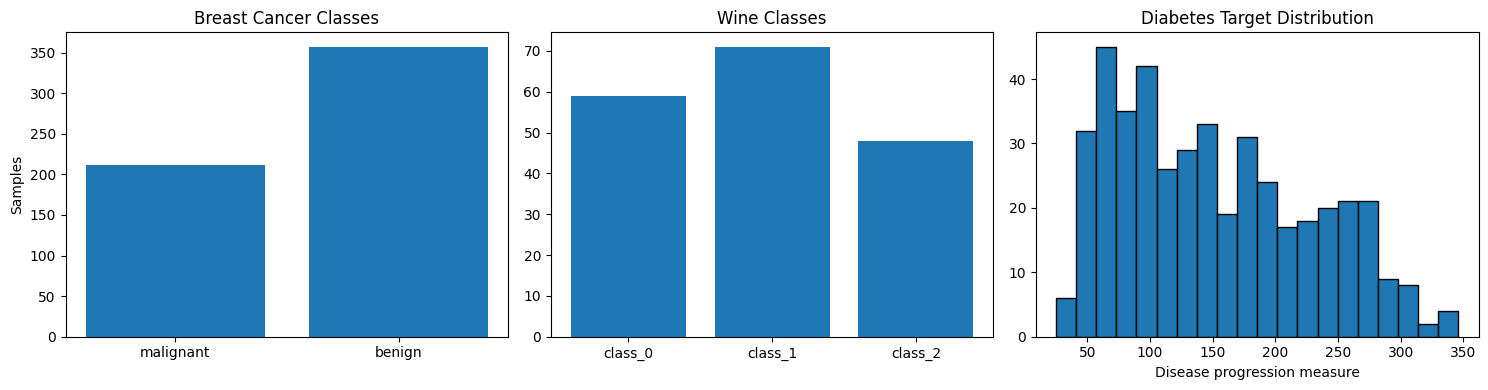

In [5]:
# Summary statistics for each dataset
print("Cancer feature statistics:")
print(X_cancer.describe().round(2))

print("\nWine feature statistics:")
print(X_wine.describe().round(2))

print("\nDiabetes feature statistics:")
print(X_diabetes.describe().round(2))

# Visualize target distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(
    cancer.target_names,
    pd.Series(y_cancer).value_counts().reindex([0, 1]).values
)
axes[0].set_title("Breast Cancer Classes")
axes[0].set_ylabel("Samples")

axes[1].bar(
    wine.target_names.astype(str),
    pd.Series(y_wine).value_counts().sort_index().values
)
axes[1].set_title("Wine Classes")

axes[2].hist(y_diabetes, bins=20, edgecolor="black")
axes[2].set_title("Diabetes Target Distribution")
axes[2].set_xlabel("Disease progression measure")

plt.tight_layout()
plt.show()

In [6]:
# Breast Cancer split
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cancer, y_cancer,
    test_size=0.20,
    random_state=42,
    stratify=y_cancer
)

# Wine split
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    X_wine, y_wine,
    test_size=0.20,
    random_state=42,
    stratify=y_wine
)

# Diabetes split (regression, so no stratification)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_diabetes, y_diabetes,
    test_size=0.20,
    random_state=42
)

print("Cancer:", Xc_train.shape, Xc_test.shape)
print("Wine:", Xw_train.shape, Xw_test.shape)
print("Diabetes:", Xd_train.shape, Xd_test.shape)

Cancer: (455, 30) (114, 30)
Wine: (142, 13) (36, 13)
Diabetes: (353, 10) (89, 10)


In [7]:
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

dt_model.fit(Xc_train, yc_train)

yc_pred = dt_model.predict(Xc_test)

print("Decision Tree Classification Report:")
print(classification_report(
    yc_test,
    yc_pred,
    target_names=cancer.target_names,
    zero_division=0
))

print("Accuracy:", accuracy_score(yc_test, yc_pred))
print("Precision (macro):",
      precision_score(yc_test, yc_pred, average="macro"))
print("Recall (macro):",
      recall_score(yc_test, yc_pred, average="macro"))
print("F1-score (macro):",
      f1_score(yc_test, yc_pred, average="macro"))

print("\nConfusion Matrix:")
print(confusion_matrix(yc_test, yc_pred))

Decision Tree Classification Report:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114

Accuracy: 0.9385964912280702
Precision (macro): 0.9323616115296429
Recall (macro): 0.9365079365079365
F1-score (macro): 0.9343480049362403

Confusion Matrix:
[[39  3]
 [ 4 68]]


In [8]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(Xw_train, yw_train)

yw_pred = rf_model.predict(Xw_test)

print("Random Forest Classification Report:")
print(classification_report(
    yw_test,
    yw_pred,
    target_names=wine.target_names,
    zero_division=0
))

print("Accuracy:", accuracy_score(yw_test, yw_pred))
print("Precision (macro):",
      precision_score(yw_test, yw_pred, average="macro"))
print("Recall (macro):",
      recall_score(yw_test, yw_pred, average="macro"))
print("F1-score (macro):",
      f1_score(yw_test, yw_pred, average="macro"))

print("\nConfusion Matrix:")
print(confusion_matrix(yw_test, yw_pred))

Random Forest Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Accuracy: 1.0
Precision (macro): 1.0
Recall (macro): 1.0
F1-score (macro): 1.0

Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]


In [9]:
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

gb_model.fit(Xd_train, yd_train)

yd_pred = gb_model.predict(Xd_test)

mae = mean_absolute_error(yd_test, yd_pred)
mse = mean_squared_error(yd_test, yd_pred)
r2 = r2_score(yd_test, yd_pred)

print("Gradient Boosting Regression Results")
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"R²:   {r2:.4f}")

# Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual": yd_test,
    "Predicted": yd_pred
})

print("\nFirst 10 predictions:")
print(comparison.head(10).round(2))

Gradient Boosting Regression Results
MAE:  42.5461
MSE:  2742.8830
R²:   0.4823

First 10 predictions:
   Actual  Predicted
0   219.0     162.00
1    70.0     178.90
2   202.0     171.60
3   230.0     264.02
4   111.0     116.27
5    84.0     109.57
6   242.0     240.58
7   272.0     201.02
8    94.0     148.79
9    96.0     149.60


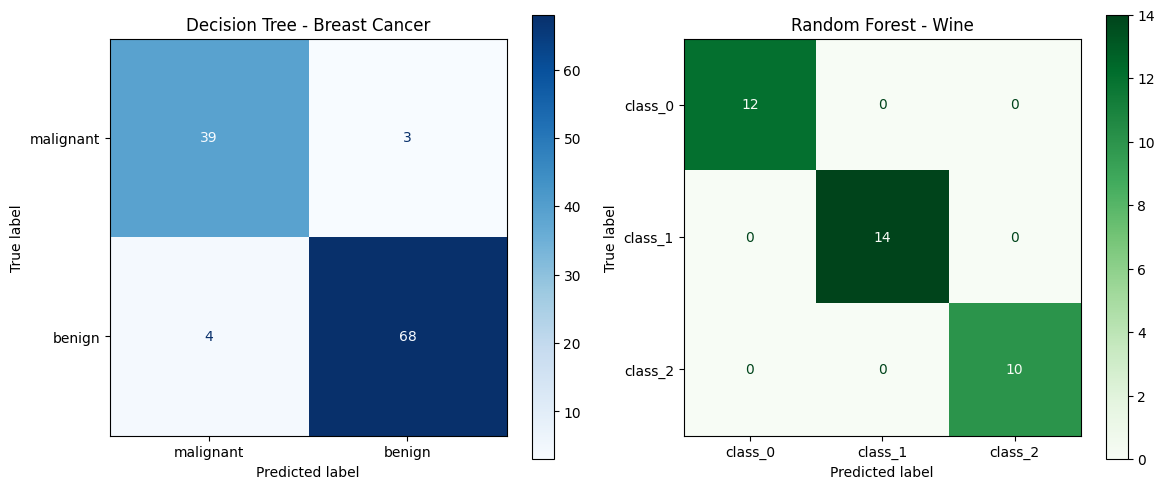

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    yc_test,
    yc_pred,
    display_labels=cancer.target_names,
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Decision Tree - Breast Cancer")

ConfusionMatrixDisplay.from_predictions(
    yw_test,
    yw_pred,
    display_labels=wine.target_names,
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("Random Forest - Wine")

plt.tight_layout()
plt.show()

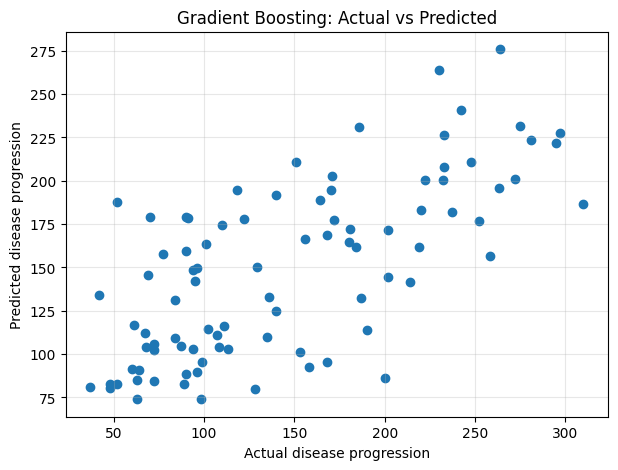

In [11]:
plt.figure(figsize=(7, 5))

plt.scatter(yd_test, yd_pred)
plt.xlabel("Actual disease progression")
plt.ylabel("Predicted disease progression")
plt.title("Gradient Boosting: Actual vs Predicted")
plt.grid(True, alpha=0.3)
plt.show()

In [12]:
classification_results = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Dataset": "Breast Cancer",
        "Accuracy": accuracy_score(yc_test, yc_pred),
        "Precision (Macro)": precision_score(
            yc_test, yc_pred, average="macro"
        ),
        "Recall (Macro)": recall_score(
            yc_test, yc_pred, average="macro"
        ),
        "F1-score (Macro)": f1_score(
            yc_test, yc_pred, average="macro"
        )
    },
    {
        "Model": "Random Forest",
        "Dataset": "Wine Recognition",
        "Accuracy": accuracy_score(yw_test, yw_pred),
        "Precision (Macro)": precision_score(
            yw_test, yw_pred, average="macro"
        ),
        "Recall (Macro)": recall_score(
            yw_test, yw_pred, average="macro"
        ),
        "F1-score (Macro)": f1_score(
            yw_test, yw_pred, average="macro"
        )
    }
])

regression_results = pd.DataFrame([{
    "Model": "Gradient Boosting",
    "Dataset": "Diabetes",
    "MAE": mean_absolute_error(yd_test, yd_pred),
    "MSE": mean_squared_error(yd_test, yd_pred),
    "R²": r2_score(yd_test, yd_pred)
}])

print("Classification Results:")
print(classification_results.round(4).to_string(index=False))

print("\nRegression Results:")
print(regression_results.round(4).to_string(index=False))

Classification Results:
        Model          Dataset  Accuracy  Precision (Macro)  Recall (Macro)  F1-score (Macro)
Decision Tree    Breast Cancer    0.9386             0.9324          0.9365            0.9343
Random Forest Wine Recognition    1.0000             1.0000          1.0000            1.0000

Regression Results:
            Model  Dataset     MAE      MSE     R²
Gradient Boosting Diabetes 42.5461 2742.883 0.4823
